# Average Counts of Any Patents and of Privacy Patents Filed in the Year, Second and Third Topic-Relevance Quartiles Among Patenting Sample Firms, 1999 to 2021

| Item | Description |
|---|---|
| Goal | The two figures of T4.2.3 for the two middle quartiles: among the sample firms with at least one KPSS patent filed in 1999 to 2017, the third quartile of the main topic-relevance score is compared with the second on the average count of any patents filed in the year per firm , 1999 to 2021: any patents (all KPSS patents, in any technology) in Figure 1 and privacy patents in Figure 2. The two outcomes are always named any patents or privacy patents so that they cannot be confused. The sample, the quartile cut, the counts, and the averages are those saved by T4.2.3; this notebook only reads and draws them. |
| Input | `output/T4.2.3/analysis_sample_firms.csv` (one row per analysis-sample firm with its relevance score and quartile) and `output/T4.2.3/average_patent_counts_by_quartile_year.csv` (one row per quartile and filing year with the number of firms and the total, average, and median counts of all and of privacy patents), both from T4.2.3; `privacy_cpc/privacy_cpc_codes_MM_102926.xlsx` for the number of privacy codes named in the Notes. |
| Output | In `output/T4.2.4`: `fig_1_average_patent_count_third_vs_second_relevance_quartile.{png,svg,pdf}` and `fig_2_average_privacy_patent_count_third_vs_second_relevance_quartile.{png,svg,pdf}`. No table: the numbers drawn are T4.2.3's. |
| Unit | A firm-year count averaged over the firms of a quartile, as in T4.2.3. |
| Analysis sample and quartiles | As in T4.2.3: the 689 firms of the all-years T3 sample with at least one KPSS patent, in any CPC class, filed in 1999 to 2017; quartiles of `MEASURE_ID` cut within those firms, 1 the lowest and 4 the highest. Here quartile 3 (`UPPER`) is drawn in RED and quartile 2 (`LOWER`) in BLUE, so that the higher-relevance group keeps the color it has in T4.2.3. |
| Average | The quartile's total count in the year divided by its fixed number of firms, a firm counting zero in a year in which it filed nothing (T4.2.3). The vertical scale is set by these two quartiles and is not the scale of the T4.2.3 figures. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and Notes in Markdown around the image, legend below the X-title, a solid BLACK zero line; axis titles and legend entries in title case at the user's request. No vertical reference line. |

See `T4.2.3` for how the sample, the quartiles, and the averages are built, `T4.2.2` for the privacy patents, and `T4.1.1` for the patent-to-firm link.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the quartiles drawn, and the wording

The project root and the S5 folders; the inputs are T4.2.3's output files. The periods and the measure name are repeated here only for the wording and must match T4.2.3.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SECTION = Path("T4 - Toy Example [Topic Relevance on Privacy Innovation]")
NOTEBOOK_NAME = "T4.2.4"  # the identifier names this notebook's output folder
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output" / NOTEBOOK_NAME
INPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output/T4.2.3"
FIRMS_FILE = INPUT_FOLDER / "analysis_sample_firms.csv"
AVERAGES_FILE = INPUT_FOLDER / "average_patent_counts_by_quartile_year.csv"
PRIVACY_CODES_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "privacy_cpc/privacy_cpc_codes_MM_102926.xlsx"

PATENTING_START = 1999  # the T4.2.3 patenting window that defines the analysis sample
PATENTING_END = 2017
PERIOD_START = 1999  # filing years drawn
PERIOD_END = 2021
UPPER, LOWER = 3, 2  # the two middle quartiles; 4 is the highest and 1 the lowest in T4.2.3
MEASURE_ID = "summaries | policy_summary | firm_summary"  # the main relevance measure, as in T4.2.3

PERIOD_WORDS = f"{PERIOD_START} to {PERIOD_END}"
SCORE_WORDS = ("the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator "
               "statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the "
               "firm's business description is closer to the policy summary")
GROUP_TITLES = {UPPER: "Third Quartile of Topic Relevance", LOWER: "Second Quartile of Topic Relevance"}
GROUP_COLORS = {UPPER: "RED", LOWER: "BLUE"}  # names only; the figure cells map them to the S3 colors
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in "
          "privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Inputs: {INPUT_FOLDER}")
print(f"Outputs: {OUTPUT_FOLDER}")


Inputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.3
Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.2.4


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")  # tick labels with a thousands separator
COLOR_BY_NAME = {"RED": RED, "BLUE": BLUE}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the T4.2.3 firm table and quartile-year averages

The firm table gives each quartile's size and score range for the Notes; the averages table gives the lines. Both must cover the four quartiles and every year of the period, and the two middle quartiles are kept for the figures.


In [4]:
analysis_firms = pd.read_csv(FIRMS_FILE, dtype={"gvkey": str})
by_quartile_year = pd.read_csv(AVERAGES_FILE)
N_PRIVACY_CODES = len(pd.read_excel(PRIVACY_CODES_FILE))
assert sorted(analysis_firms["quartile"].unique()) == [1, 2, 3, 4] and sorted(by_quartile_year["quartile"].unique()) == [1, 2, 3, 4]
assert by_quartile_year.groupby("quartile")["filing_year"].apply(lambda s: sorted(s) == list(range(PERIOD_START, PERIOD_END + 1))).all(), "a quartile without every year"
quartile_summary = analysis_firms.groupby("quartile").agg(n_firms=("gvkey", "size"), score_min=("relevance_score", "min"), score_max=("relevance_score", "max"),
                                                          patents_period=("n_patents_period", "sum"), privacy_patents_period=("n_privacy_patents_period", "sum"))
assert (by_quartile_year.groupby("quartile")["n_firms"].first() == quartile_summary["n_firms"]).all(), "firm counts differ between the two T4.2.3 files"
N_ANALYSIS = len(analysis_firms)
N_UPPER = int(quartile_summary.loc[UPPER, "n_firms"])
N_LOWER = int(quartile_summary.loc[LOWER, "n_firms"])
upper = by_quartile_year.loc[by_quartile_year["quartile"].eq(UPPER)].sort_values("filing_year").reset_index(drop=True)
lower = by_quartile_year.loc[by_quartile_year["quartile"].eq(LOWER)].sort_values("filing_year").reset_index(drop=True)
print(f"Analysis sample: {N_ANALYSIS:,} firms; third quartile {N_UPPER} firms, second quartile {N_LOWER} firms")
display(quartile_summary.round(4))
display(pd.DataFrame({"filing_year": upper["filing_year"], "mean_patents_third": upper["mean_patents"].round(1), "mean_patents_second": lower["mean_patents"].round(1),
                      "mean_privacy_third": upper["mean_privacy_patents"].round(2), "mean_privacy_second": lower["mean_privacy_patents"].round(2)}).set_index("filing_year").T)


Analysis sample: 689 firms; third quartile 172 firms, second quartile 172 firms


,n_firms,score_min,score_max,patents_period,privacy_patents_period
quartile,,,,,
1,173,0.4055,0.4900,73106,74
2,172,0.4901,0.5136,177266,74
3,172,0.5137,0.5399,194370,494
4,172,0.5401,0.6209,793398,3051


filing_year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
mean_patents_third,41.20,48.80,48.60,48.20,40.10,36.20,34.70,37.10,39.90,38.50,...,55.00,56.70,59.10,58.00,58.60,60.70,66.90,68.30,57.30,52.10
mean_patents_second,39.40,42.20,44.20,48.50,45.70,40.10,39.90,38.90,41.20,37.50,...,49.30,54.60,53.30,48.50,50.30,50.80,48.00,50.50,45.40,38.80
mean_privacy_third,0.02,0.04,0.03,0.03,0.01,0.01,0.07,0.13,0.09,0.06,...,0.10,0.19,0.19,0.13,0.09,0.13,0.23,0.33,0.33,0.37
mean_privacy_second,0.01,0.02,0.00,0.01,0.01,0.01,0.01,0.01,0.01,0.04,...,0.01,0.03,0.02,0.03,0.03,0.03,0.03,0.02,0.04,0.01


## Step 5. Figure 1: average count of any patents filed in the year per firm, third against second quartile

Two lines with markers over the filing years, RED for the third quartile and BLUE for the second; the legend below the X-title names the groups with their numbers of firms. Any patents means all KPSS patents, in any CPC class.


**Figure 1. Average Count of Any Patents Filed in the Year per Firm, Second and Third Quartiles of Topic Relevance Among Patenting Sample Firms, 1999 to 2021**

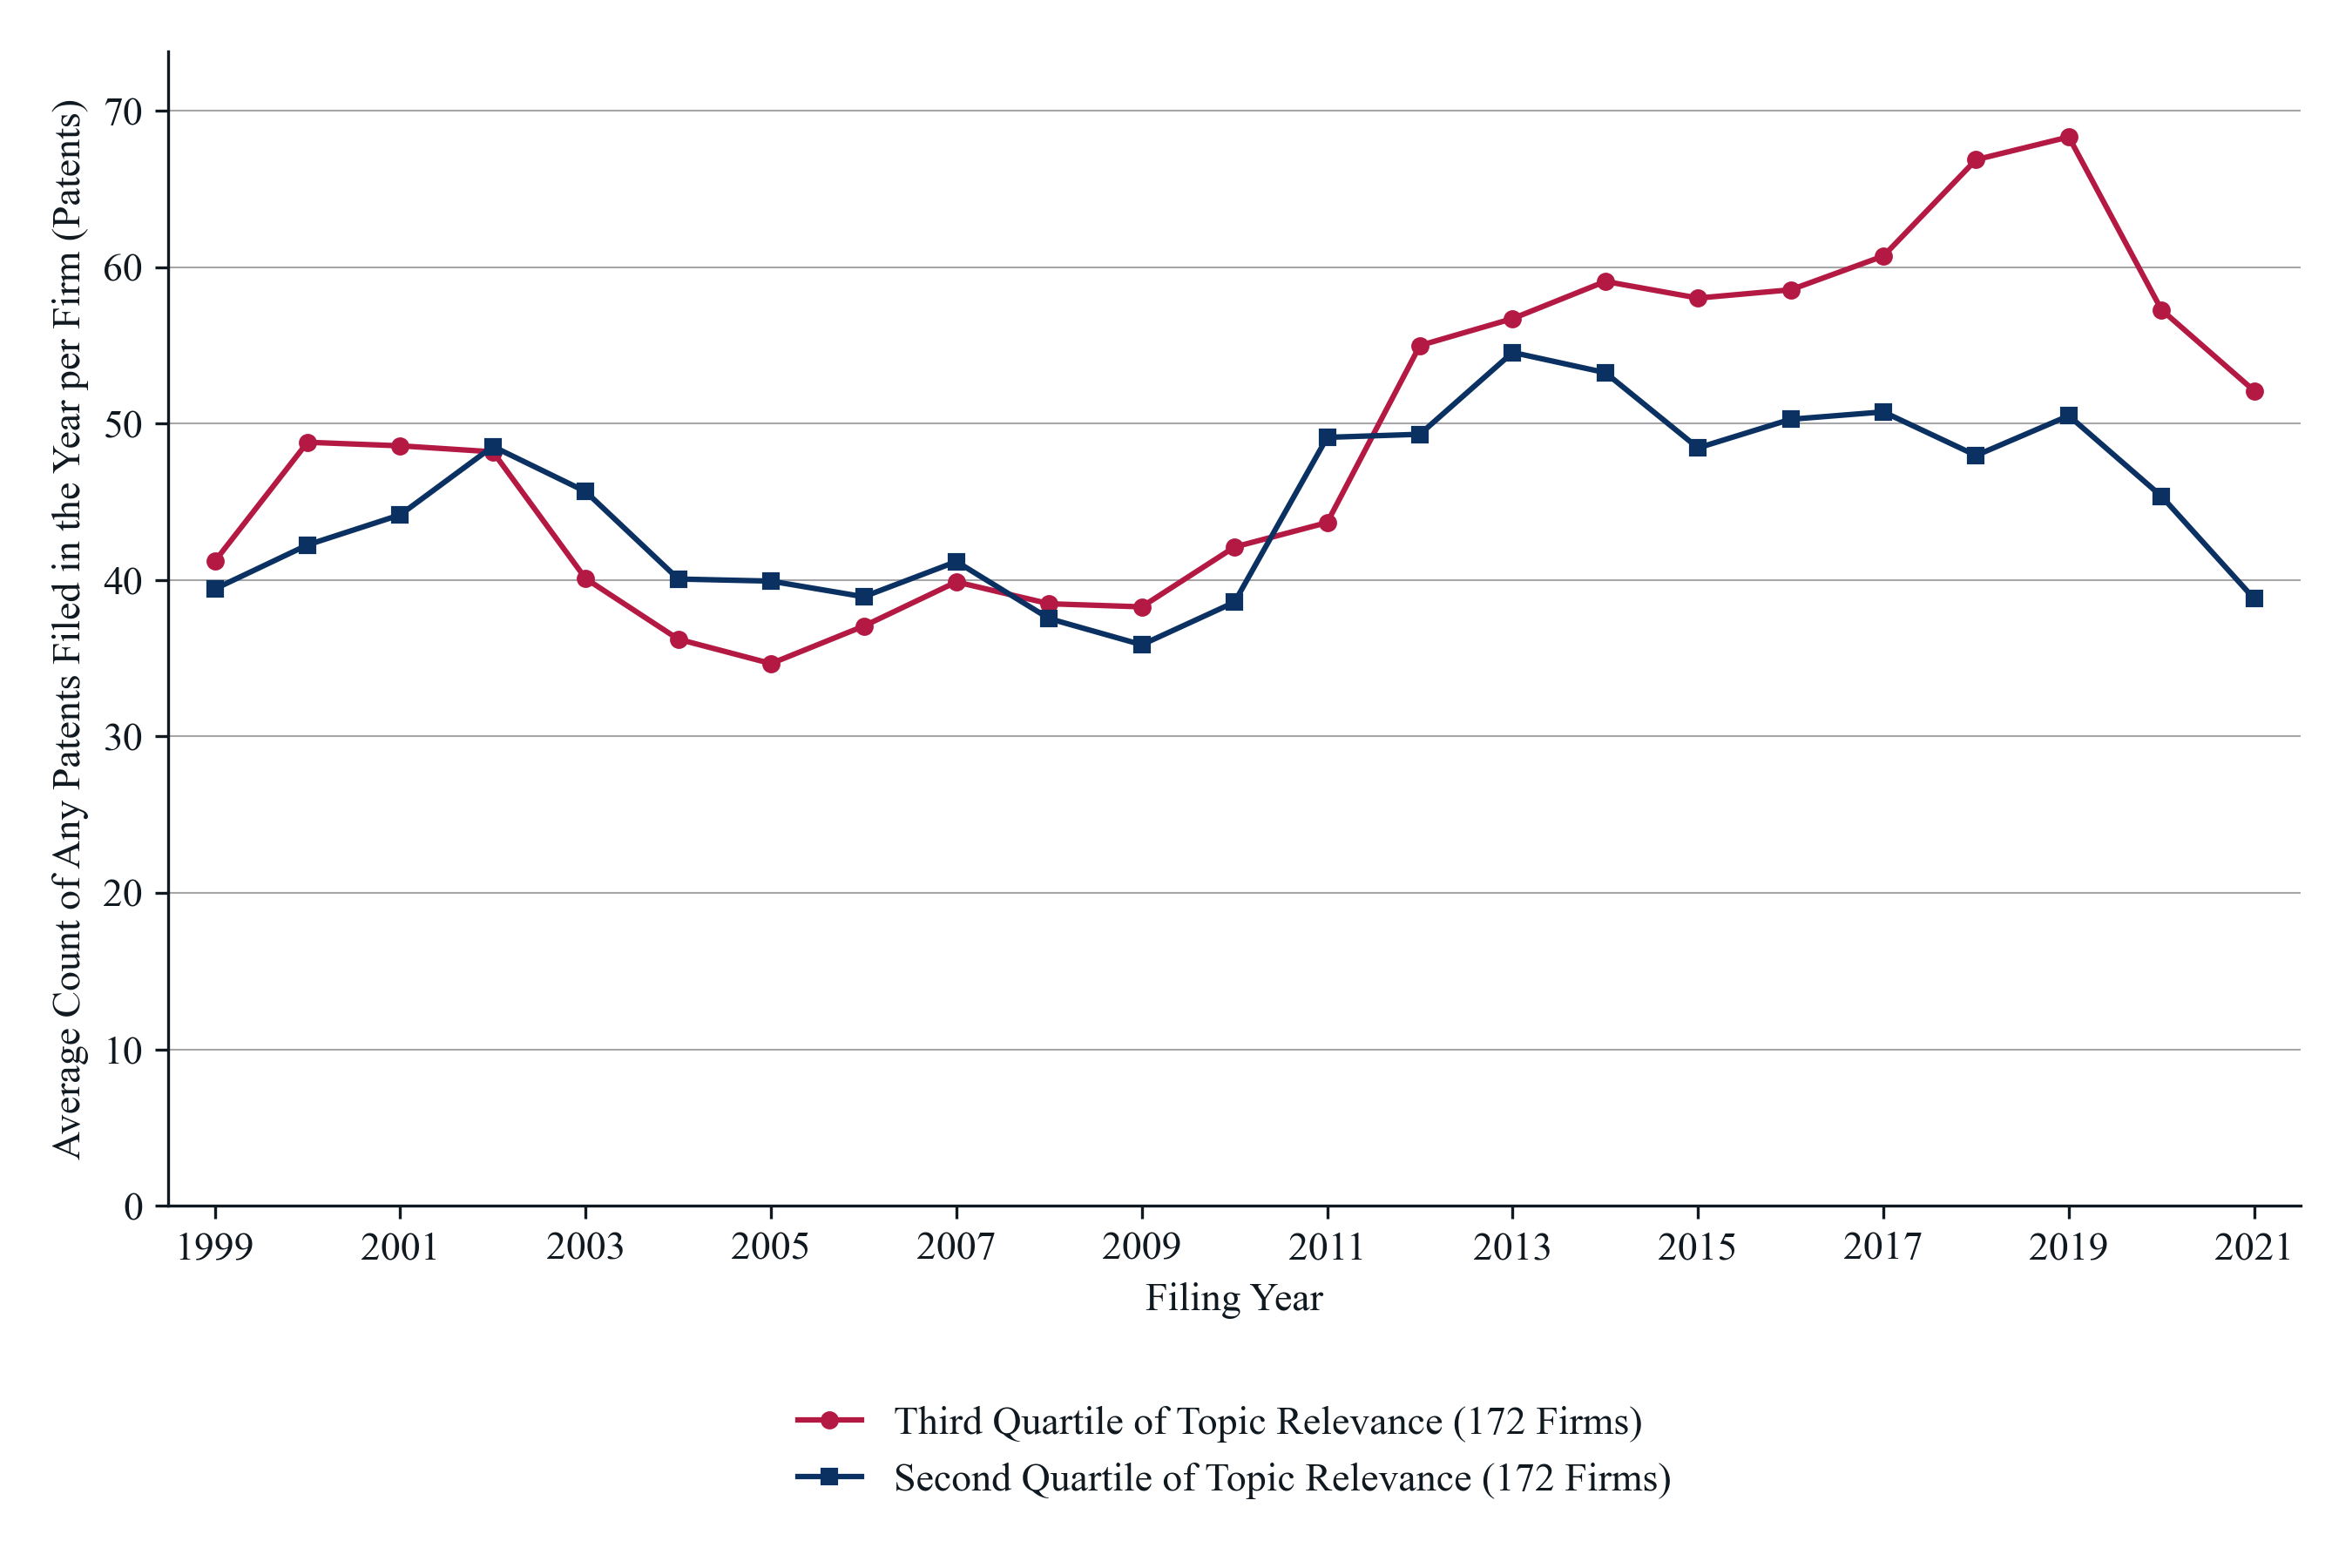

*Notes*: Each line is the average count of any patents filed in the year by the firms of the quartile, any patents meaning all KPSS patents in any CPC class, 1999 to 2021: RED for the third quartile of topic relevance and BLUE for the second. Over the period the third quartile filed 194,370 patents of any kind (1,130 per firm) and the second 177,266 (1,031 per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the T4.2.3 table. The analysis sample is the 689 firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any CPC class, filed in 1999 to 2017, as built in T4.2.3; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). Topic relevance is the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the firm's business description is closer to the policy summary. The quartiles are cut within the analysis sample: the third quartile holds the 172 firms with scores from 0.514 to 0.540 and the second the 172 firms with scores from 0.490 to 0.514; the highest and lowest quartiles are the T4.2.3 figures, and the vertical scale here is set by the two middle quartiles alone. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

In [5]:
figure_number = 1
figure_name = "fig_1_average_patent_count_third_vs_second_relevance_quartile"
title = f"Average Count of Any Patents Filed in the Year per Firm, Second and Third Quartiles of Topic Relevance Among Patenting Sample Firms, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Average Count of Any Patents Filed in the Year per Firm (Patents)"
outcome = "mean_patents"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
legend_handles = []
for quartile, table, marker in [(UPPER, upper, "o"), (LOWER, lower, "s")]:
    line, = axis.plot(table["filing_year"], table[outcome], color=COLOR_BY_NAME[GROUP_COLORS[quartile]], linewidth=1.5, marker=marker, markersize=4,
                      label=f"{GROUP_TITLES[quartile]} ({int(table['n_firms'].iloc[0]):,} Firms)", zorder=3)
    legend_handles.append(line)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(upper[outcome].max(), lower[outcome].max()) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=1, frameon=False, handlelength=1.6)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"
sample_words = (f"The analysis sample is the {N_ANALYSIS:,} firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any "
                f"CPC class, filed in {PATENTING_START} to {PATENTING_END}, as built in T4.2.3; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). "
                f"Topic relevance is {SCORE_WORDS}. The quartiles are cut within the analysis sample: the third quartile holds the {N_UPPER} firms with scores from "
                f"{quartile_summary.loc[UPPER, 'score_min']:.3f} to {quartile_summary.loc[UPPER, 'score_max']:.3f} and the second the {N_LOWER} firms with scores from "
                f"{quartile_summary.loc[LOWER, 'score_min']:.3f} to {quartile_summary.loc[LOWER, 'score_max']:.3f}; the highest and lowest quartiles are the T4.2.3 figures, and the "
                "vertical scale here is set by the two middle quartiles alone. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the "
                "period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part "
                "because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.")

notes = (f"Each line is the average count of any patents filed in the year by the firms of the quartile, any patents meaning all KPSS patents in any CPC class, {PERIOD_WORDS}: RED for the third quartile of topic "
         f"relevance and BLUE for the second. Over the period the third quartile filed {int(quartile_summary.loc[UPPER, 'patents_period']):,} patents of any kind "
         f"({quartile_summary.loc[UPPER, 'patents_period'] / N_UPPER:,.0f} per firm) and the second {int(quartile_summary.loc[LOWER, 'patents_period']):,} "
         f"({quartile_summary.loc[LOWER, 'patents_period'] / N_LOWER:,.0f} per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the T4.2.3 table. "
         f"{sample_words}")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 6. Figure 2: average count of privacy patents filed in the year per firm, third against second quartile

The same two lines for privacy patents, the patents with at least one code of the privacy code list as defined in T4.2.2.


**Figure 2. Average Count of Privacy Patents Filed in the Year per Firm, Second and Third Quartiles of Topic Relevance Among Patenting Sample Firms, 1999 to 2021**

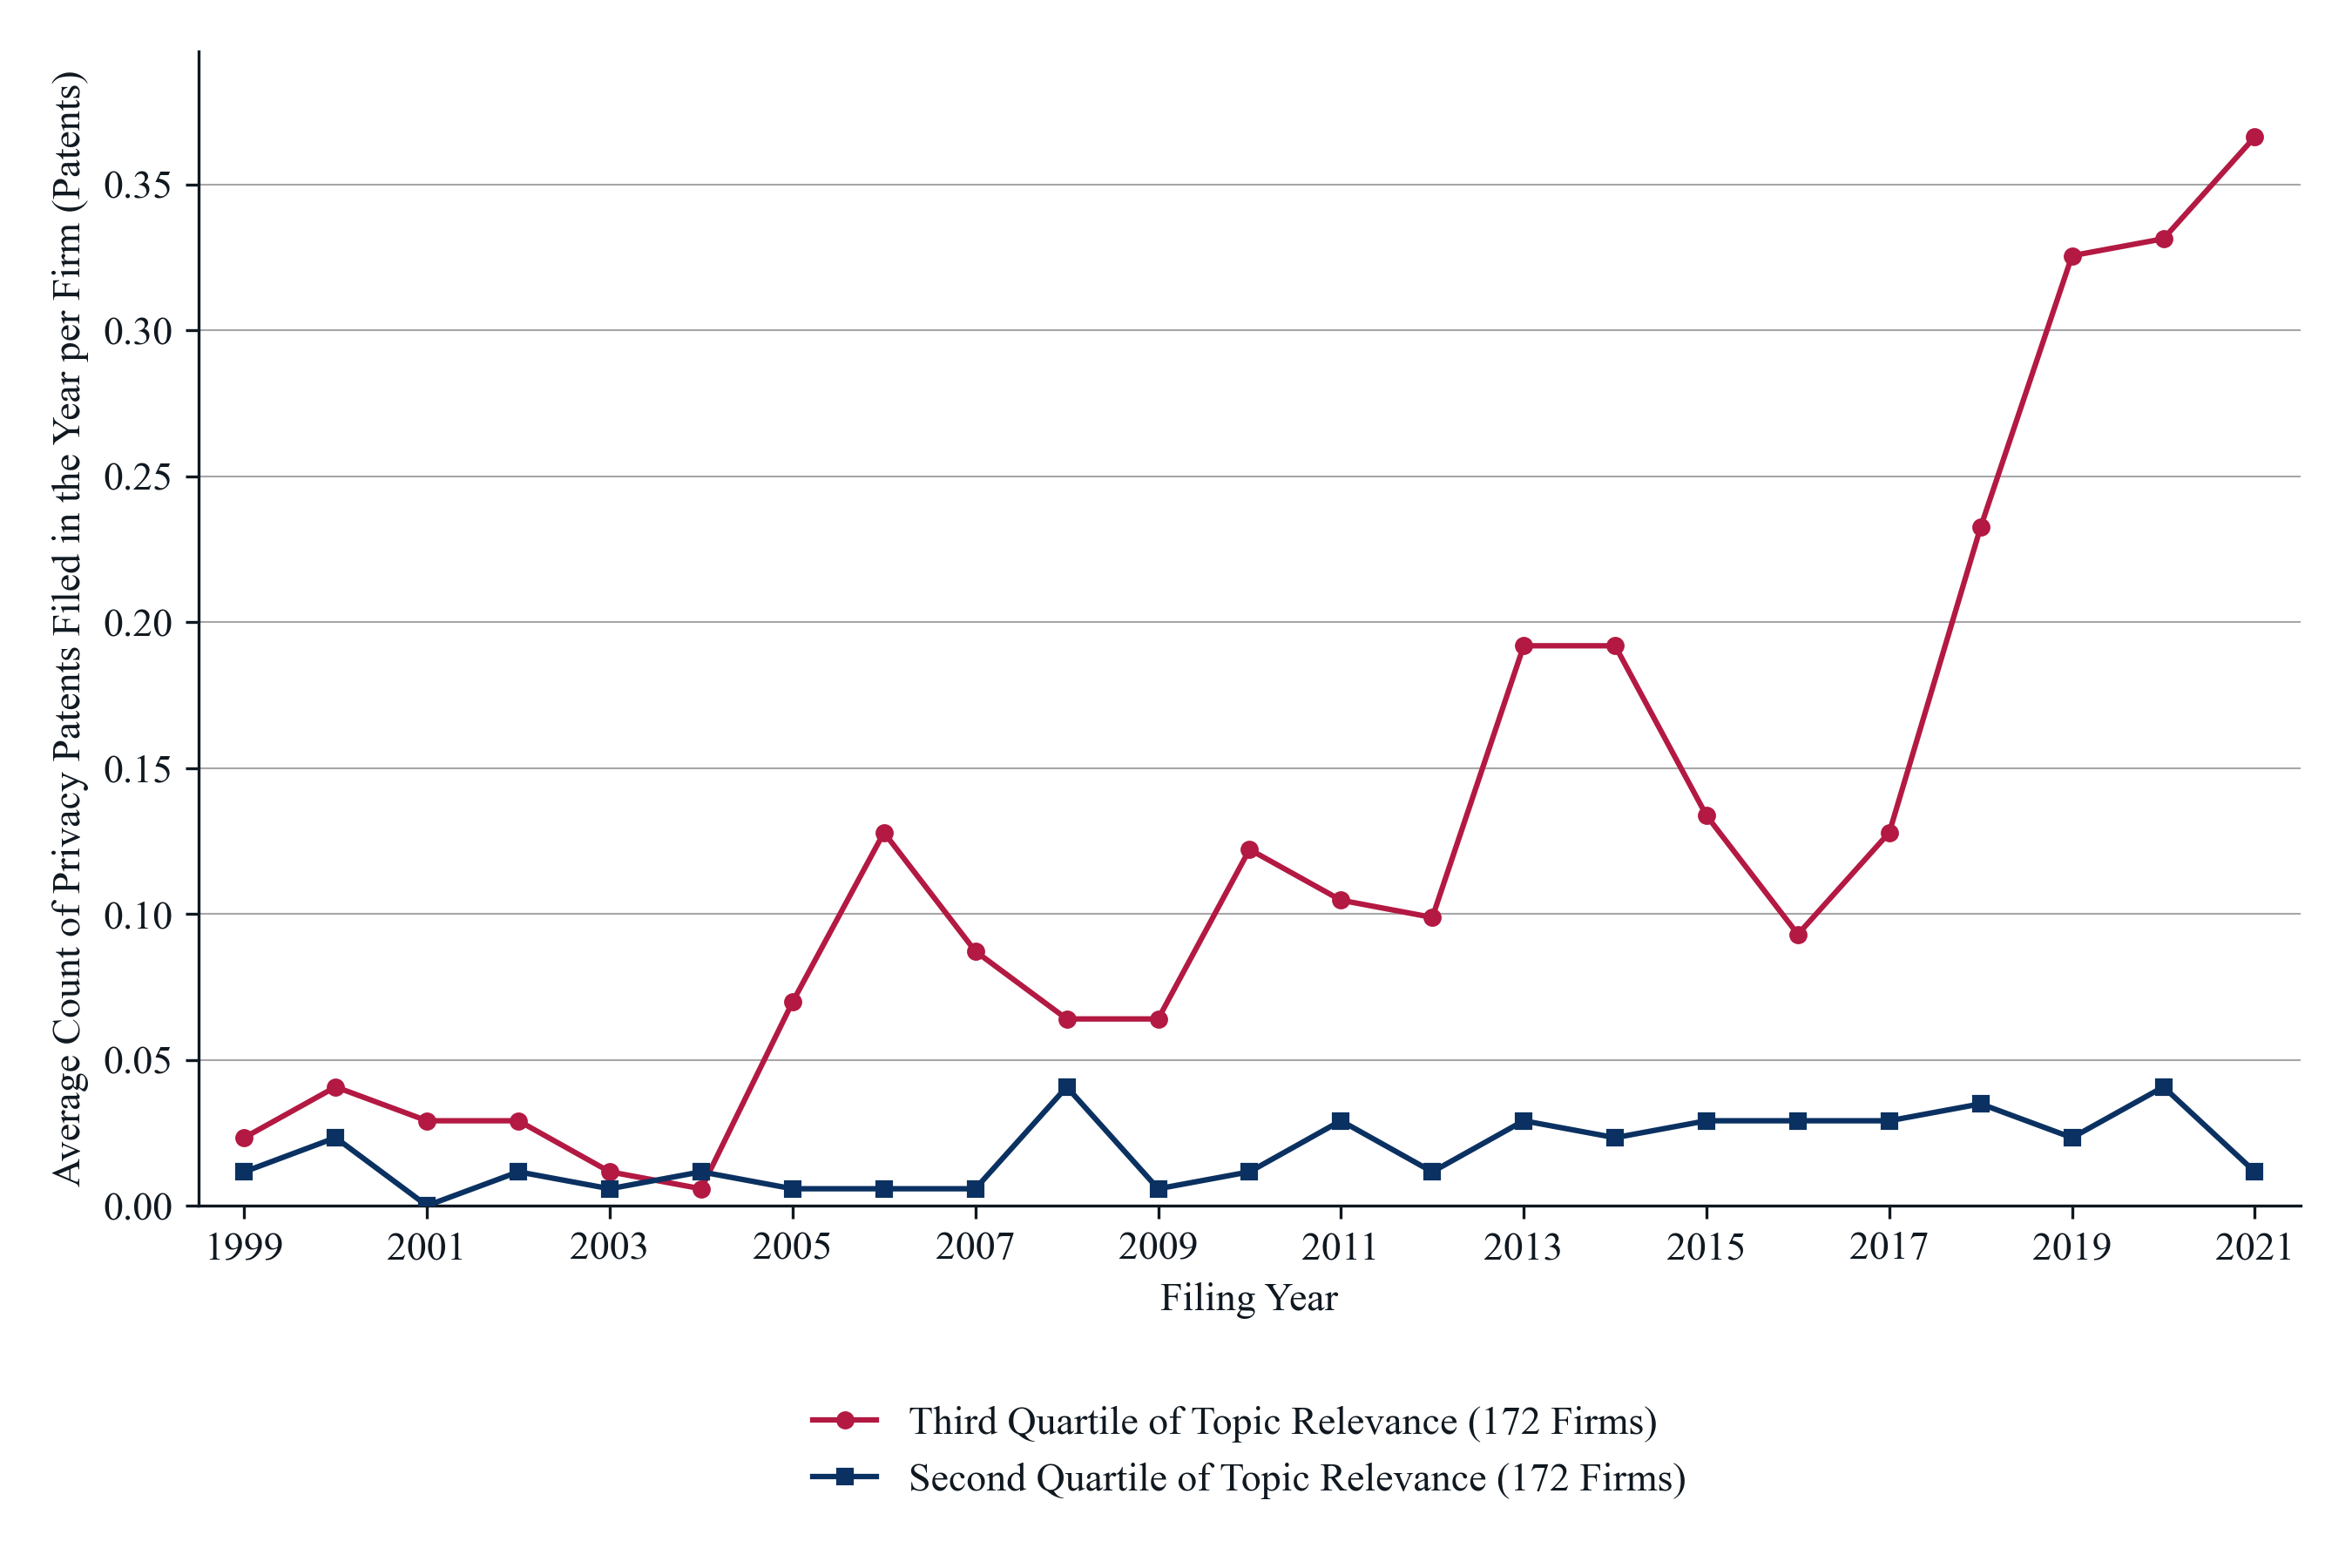

*Notes*: Each line is the average count of privacy patents filed in the year by the firms of the quartile, 1999 to 2021: RED for the third quartile of topic relevance and BLUE for the second. A privacy patent is a KPSS patent that carries at least one of the 5 CPC codes of the project's privacy code list, matched exactly as in T4.2.2. Over the period the third quartile filed 494 privacy patents (2.9 per firm) and the second 74 (0.4 per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the T4.2.3 table. The analysis sample is the 689 firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any CPC class, filed in 1999 to 2017, as built in T4.2.3; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). Topic relevance is the cosine similarity between a firm-level summary of the firm's 10-K Item 1 (Business) sections over its sample fiscal years and the policy summary of legislator statements on consumer data privacy legislation, both written by the language model (T3.8.3, the main measure of T3.9.1 to T3.9.4); a higher score means that the firm's business description is closer to the policy summary. The quartiles are cut within the analysis sample: the third quartile holds the 172 firms with scores from 0.514 to 0.540 and the second the 172 firms with scores from 0.490 to 0.514; the highest and lowest quartiles are the T4.2.3 figures, and the vertical scale here is set by the two middle quartiles alone. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes_MM_102926.xlsx; 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; authors' calculations.

In [6]:
figure_number = 2
figure_name = "fig_2_average_privacy_patent_count_third_vs_second_relevance_quartile"
title = f"Average Count of Privacy Patents Filed in the Year per Firm, Second and Third Quartiles of Topic Relevance Among Patenting Sample Firms, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Average Count of Privacy Patents Filed in the Year per Firm (Patents)"
outcome = "mean_privacy_patents"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
legend_handles = []
for quartile, table, marker in [(UPPER, upper, "o"), (LOWER, lower, "s")]:
    line, = axis.plot(table["filing_year"], table[outcome], color=COLOR_BY_NAME[GROUP_COLORS[quartile]], linewidth=1.5, marker=marker, markersize=4,
                      label=f"{GROUP_TITLES[quartile]} ({int(table['n_firms'].iloc[0]):,} Firms)", zorder=3)
    legend_handles.append(line)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, max(upper[outcome].max(), lower[outcome].max()) * 1.08)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=1, frameon=False, handlelength=1.6)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"
sample_words = (f"The analysis sample is the {N_ANALYSIS:,} firms of the all-years T3 sample (1,058 firms with a 10-K in the sample, fiscal 1999 to 2025) with at least one KPSS patent, in any "
                f"CPC class, filed in {PATENTING_START} to {PATENTING_END}, as built in T4.2.3; patents are attributed to firms through the CRSP-Compustat link in force on the filing date (T4.1.1). "
                f"Topic relevance is {SCORE_WORDS}. The quartiles are cut within the analysis sample: the third quartile holds the {N_UPPER} firms with scores from "
                f"{quartile_summary.loc[UPPER, 'score_min']:.3f} to {quartile_summary.loc[UPPER, 'score_max']:.3f} and the second the {N_LOWER} firms with scores from "
                f"{quartile_summary.loc[LOWER, 'score_min']:.3f} to {quartile_summary.loc[LOWER, 'score_max']:.3f}; the highest and lowest quartiles are the T4.2.3 figures, and the "
                "vertical scale here is set by the two middle quartiles alone. The average is the quartile's total count in the year divided by its number of firms, which is fixed over the "
                "period, so a firm counts zero in a year in which it filed nothing, including years before its listing or after its delisting. Counts in the last years are lower in part "
                "because KPSS covers granted patents and applications filed late in the period were not all granted by 2025.")

notes = (f"Each line is the average count of privacy patents filed in the year by the firms of the quartile, {PERIOD_WORDS}: RED for the third quartile of topic relevance and BLUE "
         f"for the second. A privacy patent is a KPSS patent that carries at least one of the {N_PRIVACY_CODES} CPC codes of the project's privacy code list, matched exactly as in T4.2.2. "
         f"Over the period the third quartile filed {int(quartile_summary.loc[UPPER, 'privacy_patents_period']):,} privacy patents "
         f"({quartile_summary.loc[UPPER, 'privacy_patents_period'] / N_UPPER:,.1f} per firm) and the second {int(quartile_summary.loc[LOWER, 'privacy_patents_period']):,} "
         f"({quartile_summary.loc[LOWER, 'privacy_patents_period'] / N_LOWER:,.1f} per firm); the average is pulled up by a few large patenters, and the across-firm medians are in the T4.2.3 table. "
         f"{sample_words}")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
